In [1]:
# Import library
import pandas as pd
import numpy as np
import re
import string
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [14]:
# Load dataset
file_path = "Text.csv"
df = pd.read_csv(file_path)
# Hanya mengambil kolom message untuk klasterisasi
df = df.rename(columns={'Message': 'text'})


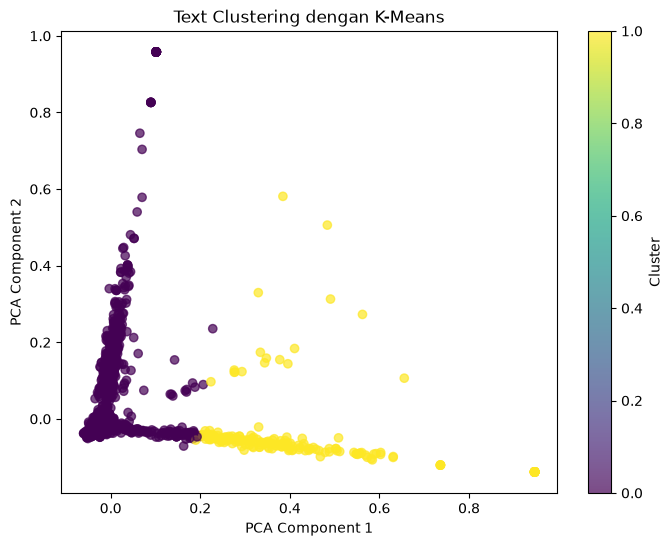

In [ ]:
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()
# Fungsi preprocessing teks
def clean_text(text):
 text = text.lower() # Lowercasing
 text = re.sub(r'\d+', '', text) # Hapus angka
 text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
 words = word_tokenize(text) # Tokenisasi
 words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
 return ' '.join(words)
# Terapkan preprocessing ke teks
df['clean_text'] = df['text'].apply(clean_text)
# Konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english') # Menggunakan stopwords dari sklearn
X = vectorizer.fit_transform(df['clean_text'])
# Tentukan jumlah klaster
num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)
# Visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()